# Quantum-Assisted Multi-Agent System Optimization for Autonomous Swarms
## Part I, Step 1 — Multi-agent drone pathfinding: data analysis, simulation and optimization

**What this notebook does?**

 A group of drones must fly from their start cells to their target cells on a shared 2D grid with obstacles, without colliding, while keeping total travel distance and mission time low. 

1. explain and represent the problem ;
2. object-oriented Python solution: `GridEnvironment`, `Agent`, `ReservationTable`, `NaivePlanner`, `PrioritizedPlanner`;
3. use **Dijkstra's algorithm** for pathfinding;
4. a **coordination mechanism**;
5. run **exploratory data analysis (EDA)**, evaluate **Scenario 1 (2 agents)** and **Scenario 2 (5 agents)**;
6. verify code with **test cases**;
7. a **quantum computing extension**.

**Environment:** self-generated 2D grid. **Requires:** numpy, pandas, matplotlib.

## 1. Understanding the problem

**Environment and representation.** The world is a 2D grid; a cell is `(row, col)`. A NumPy array stores `0` for free and `1` for obstacle. Drones move in a 4-connected way or **wait** in place, one cell per discrete time step.

**Agents.** Each drone has a unique start cell and a unique target cell.

**Movement.** Time is discrete. At each step a drone either stays or moves one cell. When a drone reaches its goal it **stays parked** there.

**Communication.** The planner is *centralised*: drones plan one after another, and each drone "broadcasts" its finished space-time path into a shared `ReservationTable`. Later drones read that table and treat the claimed `(cell, time)` slots as moving obstacles. This is the only information exchanged.

**What counts as a collision.**
* *vertex collision* — two drones occupy the same cell at the same time step;
* *edge collision* — two drones exchange cells in one step (they would pass through each other).

**Challenges.** (a) *Collisions*: independent shortest paths ignore each other. (b) *Congestion*: many paths share corridors and junctions. (c) *Conflicting paths*: someone has to give way. (d) *Scalability*: more drones means more reservations to avoid and more planning work. (e) *Parked drones* act as obstacles for everyone else, so a plan must never route someone through a goal after its owner has arrived.

In [20]:
import heapq
import itertools
import os
import random
import time
from collections import defaultdict, deque
from dataclasses import dataclass, field

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D

plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 11, "axes.labelsize": 9})
pd.set_option("display.precision", 2)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)

# Cells are (row, col). Index 0 is "wait in place"; the other four are the 4-connected moves.
MOVES = [(0, 0), (1, 0), (-1, 0), (0, 1), (0, -1)]
GRID_W, GRID_H = 10, 10     # grid of the worked example (the task suggests 10x10 or 20x20)
OBSTACLE_DENSITY = 0.15     # fraction of cells that are obstacles

In [21]:
class GridEnvironment:
    """A 2D, 4-connected grid world. grid[r, c] == 0 -> free, 1 -> obstacle."""
    FREE, OBSTACLE = 0, 1

    def __init__(self, grid):
        self.grid = np.asarray(grid, dtype=int)
        self.height, self.width = self.grid.shape

    @classmethod
    def random(cls, width, height, obstacle_density, rng):
        return cls((rng.random((height, width)) < obstacle_density).astype(int))

    def in_bounds(self, cell):
        r, c = cell
        return 0 <= r < self.height and 0 <= c < self.width

    def is_free(self, cell):
        return self.in_bounds(cell) and self.grid[cell[0], cell[1]] == self.FREE

    def neighbors(self, cell):
        """Free 4-connected neighbours (no 'wait' move here)."""
        r, c = cell
        for dr, dc in MOVES[1:]:
            nxt = (r + dr, c + dc)
            if self.is_free(nxt):
                yield nxt

    def free_cells(self):
        return [(int(r), int(c)) for r, c in zip(*np.where(self.grid == self.FREE))]

    def connected_components(self):
        """Connected components of free cells, largest first."""
        seen, comps = set(), []
        for cell in self.free_cells():
            if cell in seen:
                continue
            comp, stack = {cell}, [cell]
            seen.add(cell)
            while stack:
                u = stack.pop()
                for v in self.neighbors(u):
                    if v not in seen:
                        seen.add(v); comp.add(v); stack.append(v)
            comps.append(comp)
        return sorted(comps, key=len, reverse=True)


@dataclass
class Agent:
    """An autonomous drone with a start cell and a target cell."""
    id: int
    start: tuple
    goal: tuple
    color: str = "tab:blue"

    @property
    def manhattan(self):
        return abs(self.start[0] - self.goal[0]) + abs(self.start[1] - self.goal[1])


def make_scenario(width=GRID_W, height=GRID_H, n_agents=5, obstacle_density=OBSTACLE_DENSITY,
                  seed=0, min_trip=5):
    """Random obstacles + n agents with distinct starts and distinct goals.

    All starts/goals are drawn from the largest connected free region, so every goal is
    reachable from its start. Each trip has Manhattan length >= min_trip (no trivial trips).
    """
    rng = np.random.default_rng(seed)
    env = GridEnvironment.random(width, height, obstacle_density, rng)
    region = sorted(env.connected_components()[0])
    if len(region) < 2 * n_agents:
        raise ValueError("Not enough free cells for this many agents")
    used, starts, goals = set(), [], []
    for _ in range(n_agents):
        for _try in range(1000):               # rejection-sample one (start, goal) pair
            s, g = (region[i] for i in rng.choice(len(region), size=2, replace=False))
            if s in used or g in used:
                continue
            if abs(s[0] - g[0]) + abs(s[1] - g[1]) < min_trip:
                continue
            used.update((s, g)); starts.append(s); goals.append(g)
            break
        else:
            raise RuntimeError("Could not place all agents; use a larger grid or fewer agents")
    palette = plt.cm.tab10.colors
    agents = [Agent(i, starts[i], goals[i], palette[i % 10]) for i in range(n_agents)]
    return env, agents

## 2. Dijkstra's algorithm — static and in space-time

**Static Dijkstra** finds the shortest path from a start to a goal on the grid with unit edge costs. Complexity is O(E log V) with a binary heap. It ignores other drones, so it is the *independent baseline*.

**Space-time Dijkstra** is the same algorithm on a *time-expanded graph*. A node is `(cell, t)`. From `(u, t)` a drone can **wait** (arrive at `(u, t+1)`, cost `wait_cost`) or **move** to a neighbour (arrive at `(v, t+1)`, cost 1). A transition is forbidden if the `ReservationTable` says the target `(cell, t+1)` is taken, or that another drone is making the opposite swap. The search stops when the goal is reached **and** the drone can stay there for good. With `wait_cost = 1` the result is the *earliest conflict-free arrival*; Dijkstra guarantees it is optimal for that drone given the reservations. Complexity is O(|V|·T·log(|V|·T)) for horizon T.

In [22]:
def dijkstra_static(env, start, goal=None):
    """Classic Dijkstra on the grid (unit edge cost).

    goal given  -> returns (path, cost) or (None, inf) if unreachable (stops early at goal).
    goal = None -> returns dict {cell: shortest distance from start} for every reachable cell.
    """
    dist, prev = {start: 0}, {}
    pq = [(0, start)]
    while pq:
        d, u = heapq.heappop(pq)
        if d > dist[u]:
            continue                            # stale queue entry
        if u == goal:
            break
        for v in env.neighbors(u):
            nd = d + 1
            if nd < dist.get(v, float("inf")):
                dist[v], prev[v] = nd, u
                heapq.heappush(pq, (nd, v))
    if goal is None:
        return dist
    if goal not in dist:
        return None, float("inf")
    path, node = [goal], goal
    while node != start:
        node = prev[node]
        path.append(node)
    return path[::-1], dist[goal]


class ReservationTable:
    """Shared 'blackboard' of space-time cells already claimed by higher-priority agents.

    vertex : {(cell, t)}        -> a cell occupied at time t
    edge   : {(u, v, t)}        -> an agent moves u -> v during [t, t+1]   (to forbid swaps)
    parked : {cell: t_arrival}  -> an agent that reached its goal sits there from t_arrival forever
    last_t : {cell: t}          -> latest time a (moving) agent uses the cell
    """
    def __init__(self):
        self.vertex, self.edge, self.parked, self.last_t = set(), set(), {}, {}

    def add_path(self, path):
        for t, cell in enumerate(path):
            self.vertex.add((cell, t))
            self.last_t[cell] = max(self.last_t.get(cell, -1), t)
            if t + 1 < len(path) and path[t + 1] != cell:
                self.edge.add((cell, path[t + 1], t))
        self.parked[path[-1]] = len(path) - 1       # it stays at its final cell forever

    def vertex_blocked(self, cell, t):
        return (cell, t) in self.vertex or (cell in self.parked and t >= self.parked[cell])

    def edge_blocked(self, u, v, t):
        return (v, u, t) in self.edge               # someone moves v -> u at the same time (swap)

    def can_park(self, cell, t):
        """Can an agent sit on `cell` from time t onward without ever being run over?"""
        return self.last_t.get(cell, -1) < t and cell not in self.parked


def dijkstra_spacetime(env, start, goal, table, horizon, wait_cost=1.0):
    """Dijkstra on the time-expanded graph: a state is (cell, t).

    From (u, t) the agent may WAIT (cost = wait_cost) or MOVE to a free neighbour (cost 1),
    arriving at time t+1, provided the reservation table says the move is conflict-free.
    The search ends when the goal is reached AND the agent can stay there for good.
    Returns (path, cost, expanded_states); path[t] is the cell occupied at time t.
    """
    best = {(start, 0): 0.0}
    prev = {}
    pq = [(0.0, 0, start)]
    expanded = 0
    while pq:
        cost, t, u = heapq.heappop(pq)
        if cost > best.get((u, t), float("inf")):
            continue
        expanded += 1
        if u == goal and table.can_park(goal, t):
            path, state = [u], (u, t)
            while state in prev:
                state = prev[state]
                path.append(state[0])
            return path[::-1], cost, expanded
        if t >= horizon:
            continue
        for dr, dc in MOVES:
            v = (u[0] + dr, u[1] + dc)
            if not env.is_free(v):
                continue
            waiting = (v == u)
            if table.vertex_blocked(v, t + 1):
                continue
            if not waiting and table.edge_blocked(u, v, t):
                continue
            nc = cost + (wait_cost if waiting else 1.0)
            if nc < best.get((v, t + 1), float("inf")):
                best[(v, t + 1)] = nc
                prev[(v, t + 1)] = (u, t)
                heapq.heappush(pq, (nc, t + 1, v))
    return None, float("inf"), expanded

## 3. Coordination mechanism — prioritized planning

`NaivePlanner` is the baseline: every drone follows its own Dijkstra path.

`PrioritizedPlanner` is the coordinated method:
1. Rank the drones by **longest trip first**.
2. Plan the drones one at a time with space-time Dijkstra, adding each finished path to the `ReservationTable`.
3. Lower-priority drones route around, or wait for the higher-priority ones. Because they have shorter trips they usually have slack, so waiting rarely delays the whole mission.

In [23]:
@dataclass
class PlanResult:
    name: str
    paths: dict                 # agent id -> list of cells (index = time step) or None if it failed
    runtime_s: float
    expanded: int = 0           # number of Dijkstra states expanded (work done)
    order: list = None          # priority order that was used (coordinated planner only)
    attempts: int = 1           # priority orders tried


class NaivePlanner:
    """Baseline: every drone runs plain Dijkstra and ignores all the others."""
    name = "Independent Dijkstra (no coordination)"

    def __init__(self, env):
        self.env = env

    def plan(self, agents):
        t0 = time.perf_counter()
        paths = {a.id: dijkstra_static(self.env, a.start, a.goal)[0] for a in agents}
        return PlanResult(self.name, paths, time.perf_counter() - t0)


class PrioritizedPlanner:
    """Coordinated planning: drones plan one after another in priority order.

    Each drone runs Dijkstra in space-time, treating the paths of all higher-priority drones
    (stored in the shared ReservationTable) as moving obstacles. Priority = longest trip first.
    If some drone finds no path, a few random priority orders are tried.
    """
    name = "Dijkstra + prioritized coordination"

    def __init__(self, env, wait_cost=1.0, horizon=None, max_restarts=25, seed=0):
        self.env, self.wait_cost, self.max_restarts, self.seed = env, wait_cost, max_restarts, seed
        self.horizon = horizon or 6 * (env.width + env.height)

    def _plan_in_order(self, order):
        table, paths, expanded = ReservationTable(), {}, 0
        for agent in order:
            path, _, n = dijkstra_spacetime(self.env, agent.start, agent.goal, table,
                                            self.horizon, self.wait_cost)
            expanded += n
            paths[agent.id] = path
            table.add_path(path if path else [agent.start])   # a failed drone just stays put
        return paths, expanded

    def plan(self, agents):
        t0 = time.perf_counter()
        trip = {a.id: dijkstra_static(self.env, a.start, a.goal)[1] for a in agents}
        base = sorted(agents, key=lambda a: (-trip[a.id], a.id))
        rng = random.Random(self.seed)
        best, total_expanded, attempts = None, 0, 0
        for k in range(self.max_restarts + 1):
            order = base if k == 0 else rng.sample(agents, len(agents))
            paths, exp = self._plan_in_order(order)
            attempts += 1
            total_expanded += exp
            reached = sum(p is not None for p in paths.values())
            cost = sum(len(p) - 1 for p in paths.values() if p)
            key = (-reached, cost)
            if best is None or key < best[0]:
                best = (key, paths, order)
            if reached == len(agents):
                break
        return PlanResult(self.name, best[1], time.perf_counter() - t0, total_expanded,
                          [a.id for a in best[2]], attempts)

## 4. Performance metrics and visualisation helpers

`evaluate` turns a plan into the required metrics:

| metric | definition |
|---|---|
| **total travel distance** | total number of moves made by all drones |
| **collisions** | number of vertex + swap collision events in the executed plan |
| **% agents reaching destination** | share of drones whose path ends on their goal |
| **mission completion time** | time step at which the last drone arrives |


In [24]:
def position(path, t):
    """Where a drone is at time t (it stays on its last cell once the path ends)."""
    return path[min(t, len(path) - 1)]


def full_paths(agents, paths):
    return {a.id: (paths[a.id] if paths[a.id] else [a.start]) for a in agents}


def find_conflicts(agents, paths):
    """All collisions in the executed plan.
    vertex: two drones on the same cell at the same time step.
    swap  : two drones exchange cells in one step (they would pass through each other).
    """
    full = full_paths(agents, paths)
    ids = [a.id for a in agents]
    T = max(len(p) for p in full.values())
    events = []
    for t in range(T):
        occupied = defaultdict(list)
        for i in ids:
            occupied[position(full[i], t)].append(i)
        for cell, who in occupied.items():
            for i, j in itertools.combinations(sorted(who), 2):
                events.append({"type": "vertex", "t": t, "agents": (i, j), "cell": cell})
        for i, j in itertools.combinations(ids, 2):
            a0, a1 = position(full[i], t), position(full[i], t + 1)
            b0, b1 = position(full[j], t), position(full[j], t + 1)
            if a0 != a1 and a0 == b1 and b0 == a1:
                events.append({"type": "swap", "t": t, "agents": (i, j), "cell": (a0, a1)})
    return events


def evaluate(env, agents, result):
    """Performance metrics of one plan (one row of the results table)."""
    full = full_paths(agents, result.paths)
    events = find_conflicts(agents, result.paths)
    reached = {a.id: result.paths[a.id] is not None and full[a.id][-1] == a.goal for a in agents}
    arrival = {i: len(full[i]) - 1 for i in full if reached[i]}
    moves = {i: sum(1 for u, v in zip(p, p[1:]) if u != v) for i, p in full.items()}
    ideal = sum(dijkstra_static(env, a.start, a.goal)[1] for a in agents)   # lower bound
    involved = {i for e in events for i in e["agents"]}
    return {
        "method": result.name,
        "agents": len(agents),
        "total_distance": sum(moves.values()),
        "ideal_distance": ideal,
        "collisions": len(events),
        "vertex_collisions": sum(e["type"] == "vertex" for e in events),
        "swap_collisions": sum(e["type"] == "swap" for e in events),
        "agents_in_conflict": len(involved),
        "reached_pct": 100.0 * sum(reached.values()) / len(agents),
        "completion_time": max(arrival.values()) if all(reached.values()) else float("nan"),
        "sum_of_arrival_times": sum(arrival.values()) if all(reached.values()) else float("nan"),
        "wait_steps": sum(len(p) - 1 - moves[i] for i, p in full.items()),
        "runtime_s": result.runtime_s,
        "expanded_states": result.expanded,
    }

In [25]:
OBST_CMAP = ListedColormap(["#ffffff", "#3a3f4b"])
CONFLICT_COLOR = "#d62728"


def draw_grid(ax, env):
    ax.imshow(env.grid, cmap=OBST_CMAP, vmin=0, vmax=1, origin="upper")
    ax.set_xticks(np.arange(-0.5, env.width, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, env.height, 1), minor=True)
    ax.grid(which="minor", color="#d5d9df", linewidth=0.5)
    step = 1 if env.width <= 12 else 5
    ax.set_xticks(range(0, env.width, step)); ax.set_yticks(range(0, env.height, step))
    ax.tick_params(which="both", length=0, labelsize=7)
    ax.set_xlim(-0.5, env.width - 0.5); ax.set_ylim(env.height - 0.5, -0.5)
    ax.set_aspect("equal")


def plot_paths(ax, env, agents, paths, events=None, title=""):
    """Draw every drone's path (slightly offset so overlapping paths stay visible)."""
    draw_grid(ax, env)
    full = full_paths(agents, paths)
    n = len(agents)
    for k, a in enumerate(agents):
        off = (k - (n - 1) / 2) * 0.07
        p = full[a.id]
        ax.plot([c + off for _, c in p], [r + off for r, _ in p], "-", color=a.color, lw=2, alpha=0.9)
        ax.plot(a.start[1], a.start[0], "o", ms=10, mfc=a.color, mec="white", mew=1.5, zorder=4)
        ax.plot(a.goal[1], a.goal[0], "*", ms=15, mfc=a.color, mec="black", mew=0.8, zorder=4)
        ax.text(a.start[1], a.start[0], str(a.id), color="white", ha="center", va="center",
                fontsize=6.5, fontweight="bold", zorder=5)
    for e in events or []:
        if e["type"] == "vertex":
            r, c = e["cell"]
        else:
            (r0, c0), (r1, c1) = e["cell"]; r, c = (r0 + r1) / 2, (c0 + c1) / 2
        ax.plot(c, r, "X", ms=11, mfc=CONFLICT_COLOR, mec="white", mew=1, zorder=6)
    ax.set_title(title)


def legend_handles(with_conflicts=True):
    h = [Line2D([], [], marker="o", ls="", mfc="gray", mec="white", ms=9, label="start"),
         Line2D([], [], marker="*", ls="", mfc="gray", mec="black", ms=12, label="goal"),
         Line2D([], [], marker="s", ls="", mfc="#3a3f4b", mec="#3a3f4b", ms=8, label="obstacle")]
    if with_conflicts:
        h.append(Line2D([], [], marker="X", ls="", mfc=CONFLICT_COLOR, mec="white", ms=10, label="collision"))
    return h


def plot_snapshots(env, agents, paths, times, events=None, suptitle=""):
    """Positions of all drones at selected time steps (a 'film strip' of the simulation)."""
    full = full_paths(agents, paths)
    fig, axes = plt.subplots(1, len(times), figsize=(3.3 * len(times), 3.7))
    axes = np.atleast_1d(axes)
    for ax, t in zip(axes, times):
        draw_grid(ax, env)
        for a in agents:
            ax.plot(a.goal[1], a.goal[0], "*", ms=12, mfc="none", mec=a.color, mew=1.2, zorder=3)
            trail = full[a.id][: t + 1]
            ax.plot([c for _, c in trail], [r for r, _ in trail], "-", color=a.color, lw=1.2, alpha=0.5)
            r, c = position(full[a.id], t)
            ax.plot(c, r, "o", ms=13, mfc=a.color, mec="white", mew=1.5, zorder=5)
            ax.text(c, r, str(a.id), color="white", ha="center", va="center", fontsize=7,
                    fontweight="bold", zorder=6)
        for e in events or []:
            if e["t"] == t and e["type"] == "vertex":
                r, c = e["cell"]
                ax.plot(c, r, "o", ms=24, mfc="none", mec=CONFLICT_COLOR, mew=2.5, zorder=7)
        ax.set_title(f"t = {t}")
    fig.suptitle(suptitle, y=1.02, fontsize=11)
    fig.tight_layout()
    return fig


def congestion_map(env, agents, paths):
    """How many drones' paths cross each cell."""
    heat = np.zeros(env.grid.shape)
    for p in full_paths(agents, paths).values():
        for cell in set(p):
            heat[cell] += 1
    return np.ma.masked_where(env.grid == 1, heat)


def save_gif(env, agents, paths, filename, events=None, fps=3):
    """Optional: animated GIF of the simulation (needs Pillow)."""
    from matplotlib.animation import FuncAnimation, PillowWriter
    full = full_paths(agents, paths)
    T = max(len(p) for p in full.values())
    fig, ax = plt.subplots(figsize=(4.6, 4.8))

    def frame(t):
        ax.clear(); draw_grid(ax, env)
        for a in agents:
            ax.plot(a.goal[1], a.goal[0], "*", ms=13, mfc="none", mec=a.color, mew=1.3)
            trail = full[a.id][: t + 1]
            ax.plot([c for _, c in trail], [r for r, _ in trail], "-", color=a.color, lw=1.2, alpha=0.5)
            r, c = position(full[a.id], t)
            ax.plot(c, r, "o", ms=15, mfc=a.color, mec="white", mew=1.5, zorder=5)
            ax.text(c, r, str(a.id), color="white", ha="center", va="center", fontsize=8, fontweight="bold", zorder=6)
        for e in events or []:
            if e["t"] == t and e["type"] == "vertex":
                ax.plot(e["cell"][1], e["cell"][0], "o", ms=26, mfc="none", mec=CONFLICT_COLOR, mew=2.5, zorder=7)
        ax.set_title(f"t = {t}")

    FuncAnimation(fig, frame, frames=T, interval=1000 // fps).save(filename, writer=PillowWriter(fps=fps))
    plt.close(fig)

## 5. Exploratory data analysis (EDA)

**Worked example.** I use the first random seed for which the independent shortest paths really collide in *both* scenarios — if nothing collides there is nothing to coordinate. It is only the example.

In [26]:
def pick_demo_seed(width, height, n_agents=5, density=OBSTACLE_DENSITY):
    """First seed whose independent shortest paths actually collide in BOTH scenarios (2 and 5 drones).
    If nothing collides there is nothing to coordinate, so the worked example would show nothing.
    The unbiased, many-seed picture is in the Monte-Carlo section further down."""
    for seed in range(1000):
        e, ag = make_scenario(width, height, n_agents, density, seed)
        if all(find_conflicts(ag[:n], NaivePlanner(e).plan(ag[:n]).paths) for n in (2, n_agents)):
            return seed

DEMO_SEED = pick_demo_seed(GRID_W, GRID_H)
env, agents = make_scenario(GRID_W, GRID_H, 5, OBSTACLE_DENSITY, DEMO_SEED)
scenarios = {"Scenario 1 (2 agents)": agents[:2], "Scenario 2 (5 agents)": agents}
print(f"Worked example: {GRID_W}x{GRID_H} grid, obstacle density {OBSTACLE_DENSITY}, seed {DEMO_SEED}")

Worked example: 10x10 grid, obstacle density 0.15, seed 0


**5.1 Summary statistics of the environment**

In [27]:
region = env.connected_components()
env_summary = pd.Series({
    "grid size": f"{env.height} x {env.width}",
    "total cells": env.grid.size,
    "obstacle cells": int(env.grid.sum()),
    "obstacle density": env.grid.mean(),
    "free cells": int((env.grid == 0).sum()),
    "connected free regions": len(region),
    "cells in largest region": len(region[0]),
    "agents": len(agents),
}, name="value")
env_summary.to_frame()

,value
grid size,10 x 10
total cells,100
obstacle cells,15
obstacle density,0.15
free cells,85
connected free regions,2
cells in largest region,82
agents,5


**5.2 Agents: starts, targets and distances**

In [28]:
ideal_paths = {a.id: dijkstra_static(env, a.start, a.goal) for a in agents}
agent_table = pd.DataFrame({
    "agent": [a.id for a in agents],
    "start (row,col)": [a.start for a in agents],
    "goal (row,col)": [a.goal for a in agents],
    "Manhattan dist": [a.manhattan for a in agents],
    "Dijkstra shortest path": [ideal_paths[a.id][1] for a in agents],
}).set_index("agent")
agent_table["detour ratio"] = agent_table["Dijkstra shortest path"] / agent_table["Manhattan dist"]
print("Detour ratio = shortest path / Manhattan distance (1.0 means obstacles cost nothing).")
agent_table

Detour ratio = shortest path / Manhattan distance (1.0 means obstacles cost nothing).


,"start (row,col)","goal (row,col)",Manhattan dist,Dijkstra shortest path,detour ratio
agent,,,,,
0,"(5, 0)","(2, 7)",10,10,1.0
1,"(1, 8)","(9, 1)",15,15,1.0
2,"(3, 0)","(4, 4)",5,5,1.0
3,"(7, 5)","(8, 0)",6,6,1.0
4,"(1, 9)","(5, 4)",9,9,1.0


**5.3 Visualisation of positions, obstacles, destinations and the individually shortest paths**

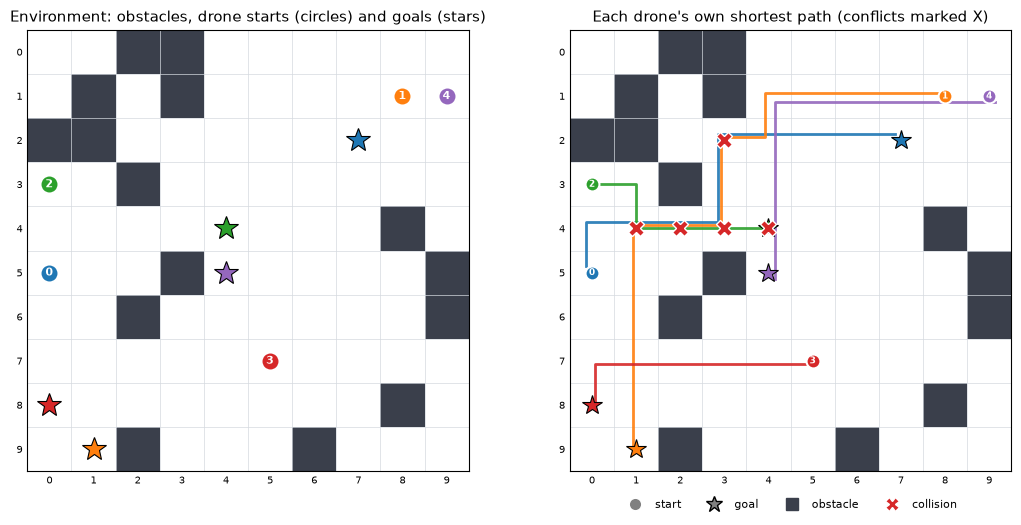

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
# (a) the world; (b) each drone's individually shortest path (no coordination yet)
draw_grid(axes[0], env)
for a in agents:
    axes[0].plot(a.start[1], a.start[0], "o", ms=13, mfc=a.color, mec="white", mew=1.5, zorder=4)
    axes[0].plot(a.goal[1], a.goal[0], "*", ms=18, mfc=a.color, mec="black", mew=0.8, zorder=4)
    axes[0].text(a.start[1], a.start[0], str(a.id), color="white", ha="center", va="center", fontsize=8, fontweight="bold", zorder=5)
axes[0].set_title("Environment: obstacles, drone starts (circles) and goals (stars)")
naive_plan = NaivePlanner(env).plan(agents)
naive_events = find_conflicts(agents, naive_plan.paths)
plot_paths(axes[1], env, agents, naive_plan.paths, naive_events,
           "Each drone's own shortest path (conflicts marked X)")
axes[1].legend(handles=legend_handles(), loc="upper center", bbox_to_anchor=(0.5, -0.04), ncol=4, fontsize=8, frameon=False)
fig.tight_layout()
plt.show()

**5.4 Analysis of travel distances and potential conflicts.** Two independent paths *overlap in space* often, but only collide when both drones are on the shared cell at the same moment.

In [30]:
# Potential conflicts: where do the independent shortest paths overlap in space, and when in time?
pairs = []
for i, j in itertools.combinations([a.id for a in agents], 2):
    shared = set(naive_plan.paths[i]) & set(naive_plan.paths[j])
    clashes = [e for e in naive_events if e["agents"] == (i, j)]
    pairs.append({"pair": f"{i} & {j}", "shared cells (spatial overlap)": len(shared),
                  "actual collisions (same cell, same time)": len(clashes)})
pair_table = pd.DataFrame(pairs)
print(f"Pairs whose paths overlap in space: {(pair_table.iloc[:, 1] > 0).sum()} of {len(pair_table)}; "
      f"pairs that really collide in time: {(pair_table.iloc[:, 2] > 0).sum()}")
display_table = pair_table[pair_table.iloc[:, 1] > 0].reset_index(drop=True)
display_table

Pairs whose paths overlap in space: 7 of 10; pairs that really collide in time: 3


,pair,shared cells (spatial overlap),"actual collisions (same cell, same time)"
0,0 & 1,6,1
1,0 & 2,3,3
2,0 & 4,1,0
3,1 & 2,3,0
4,1 & 3,1,0
5,1 & 4,6,0
6,2 & 4,1,1


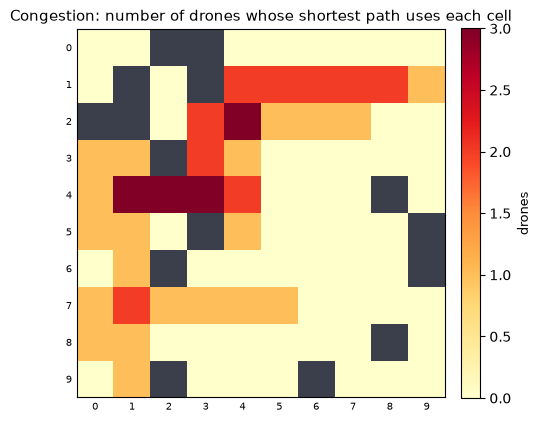

In [31]:
fig, ax = plt.subplots(figsize=(5.2, 4.8))
heat = congestion_map(env, agents, naive_plan.paths)
im = ax.imshow(heat, cmap="YlOrRd", vmin=0, vmax=max(2, heat.max()), origin="upper")
ax.imshow(np.ma.masked_where(env.grid == 0, env.grid), cmap=ListedColormap(["#3a3f4b"]), origin="upper")
ax.set_xticks(range(env.width)); ax.set_yticks(range(env.height)); ax.tick_params(labelsize=7, length=0)
ax.set_title("Congestion: number of drones whose shortest path uses each cell")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="drones")
plt.show()

**5.5 Trip lengths and obstacle detours over many random worlds**. Most trips are not lengthened by obstacles (detour ratio 1.0); a few need a detour.

grid              10x10   20x20
manhattan count  500.00  500.00
          mean     8.06   14.15
          std      2.45    6.06
          min      5.00    5.00
          25%      6.00    9.00
          50%      8.00   14.00
          75%     10.00   18.00
          max     16.00   33.00
shortest  count  500.00  500.00
          mean     8.68   14.83
          std      2.73    6.09
          min      5.00    5.00
          25%      6.00   10.00
          50%      8.00   15.00
          75%     10.25   19.00
          max     19.00   33.00
detour    count  500.00  500.00
          mean     1.09    1.06
          std      0.21    0.16
          min      1.00    1.00
          25%      1.00    1.00
          50%      1.00    1.00
          75%      1.00    1.00
          max      2.67    2.43

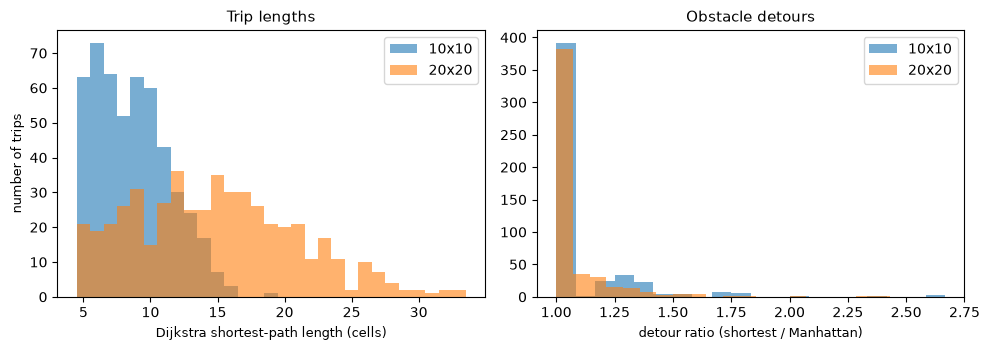

In [32]:
# How do trip lengths and obstacle detours behave in general? (100 random 10x10 and 20x20 worlds, 5 drones each)
rows = []
for (w, h) in [(10, 10), (20, 20)]:
    for s in range(100):
        e, ag = make_scenario(w, h, 5, OBSTACLE_DENSITY, seed=5000 + s)
        for a in ag:
            sp = dijkstra_static(e, a.start, a.goal)[1]
            rows.append({"grid": f"{w}x{h}", "manhattan": a.manhattan, "shortest": sp, "detour": sp / a.manhattan})
eda = pd.DataFrame(rows)
display(eda.groupby("grid")[["manhattan", "shortest", "detour"]].describe().T.round(2))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for g, col in zip(["10x10", "20x20"], ["tab:blue", "tab:orange"]):
    d = eda[eda.grid == g]
    axes[0].hist(d.shortest, bins=np.arange(4.5, eda.shortest.max() + 1.5), alpha=0.6, color=col, label=g)
    axes[1].hist(d.detour, bins=20, alpha=0.6, color=col, label=g)
axes[0].set_xlabel("Dijkstra shortest-path length (cells)"); axes[0].set_ylabel("number of trips"); axes[0].legend()
axes[1].set_xlabel("detour ratio (shortest / Manhattan)"); axes[1].legend()
axes[0].set_title("Trip lengths"); axes[1].set_title("Obstacle detours")
fig.tight_layout(); plt.show()

## 6. Experimental evaluation — Scenario 1 (2 agents) and Scenario 2 (5 agents)

Each scenario is solved by both planners and scored on the metrics above.

In [33]:
SHORT = {NaivePlanner.name: "Independent (naive)", PrioritizedPlanner.name: "Coordinated"}
rows, plans = [], {}
for label, ag in scenarios.items():
    for planner in (NaivePlanner(env), PrioritizedPlanner(env)):
        res = planner.plan(ag)
        row = evaluate(env, ag, res)
        row["scenario"], row["method"] = label, SHORT[row["method"]]
        rows.append(row)
        plans[(label, row["method"])] = res
results = pd.DataFrame(rows)

main_cols = ["scenario", "method", "total_distance", "ideal_distance", "collisions",
             "reached_pct", "completion_time", "wait_steps", "runtime_s"]
results[main_cols].set_index(["scenario", "method"])

total_distance  ideal_distance  collisions  reached_pct  completion_time  wait_steps  runtime_s
scenario              method                                                                                                              
Scenario 1 (2 agents) Independent (naive)              25              25           1        100.0               15           0   6.27e-04
                      Coordinated                      25              25           0        100.0               15           0   7.17e-03
Scenario 2 (5 agents) Independent (naive)              45              45           5        100.0               15           0   8.08e-04
                      Coordinated                      47              45           0        100.0               15           2   1.09e-02

**Per-drone detail (Scenario 2, coordinated)** — who waited, who detoured, and why the mission time does not grow:

In [34]:
# Per-drone detail for the 5-agent scenario under coordination
label = "Scenario 2 (5 agents)"
res = plans[(label, "Coordinated")]
detail = []
for pos_in_order, aid in enumerate(res.order):
    a = agents[aid]; p = res.paths[aid]
    moves = sum(1 for u, v in zip(p, p[1:]) if u != v)
    detail.append({"priority": pos_in_order + 1, "agent": aid,
                   "shortest possible": ideal_paths[aid][1], "moves made": moves,
                   "waits": len(p) - 1 - moves, "arrival time": len(p) - 1,
                   "delay vs shortest": (len(p) - 1) - ideal_paths[aid][1]})
pd.DataFrame(detail).set_index("priority")

,agent,shortest possible,moves made,waits,arrival time,delay vs shortest
priority,,,,,,
1,1,15,15,0,15,0
2,0,10,10,0,10,0
3,4,9,9,0,9,0
4,3,6,6,0,6,0
5,2,5,7,2,9,4


**Planned paths, independent vs coordinated** (red X = collision):

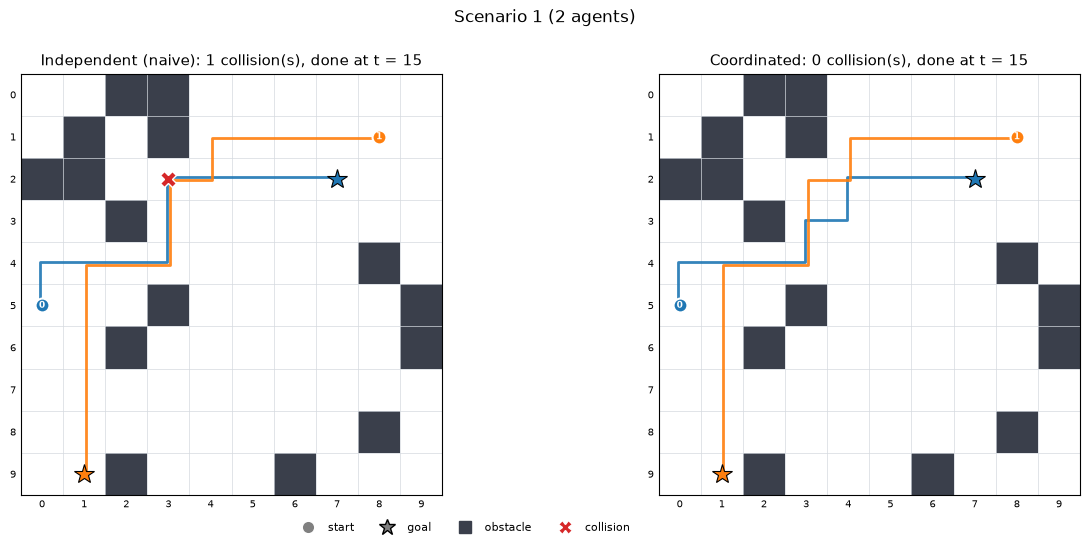

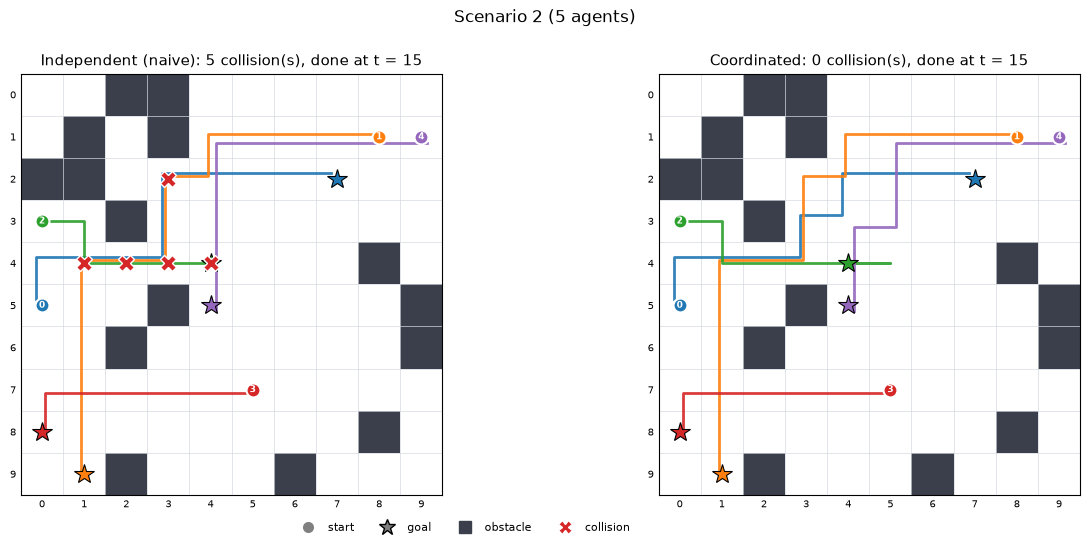

In [35]:
for label, ag in scenarios.items():
    fig, axes = plt.subplots(1, 2, figsize=(11, 5.4))
    for ax, method in zip(axes, ["Independent (naive)", "Coordinated"]):
        res = plans[(label, method)]
        ev = find_conflicts(ag, res.paths)
        m = results[(results.scenario == label) & (results.method == method)].iloc[0]
        plot_paths(ax, env, ag, res.paths, ev,
                   f"{method}: {int(m.collisions)} collision(s), done at t = {m.completion_time:.0f}")
    axes[0].legend(handles=legend_handles(), loc="upper center", bbox_to_anchor=(1.05, -0.04), ncol=4, fontsize=8, frameon=False)
    fig.suptitle(label, fontsize=12, y=1.0)
    fig.tight_layout()
    plt.show()

**Simulation film strip** — drone positions over time:

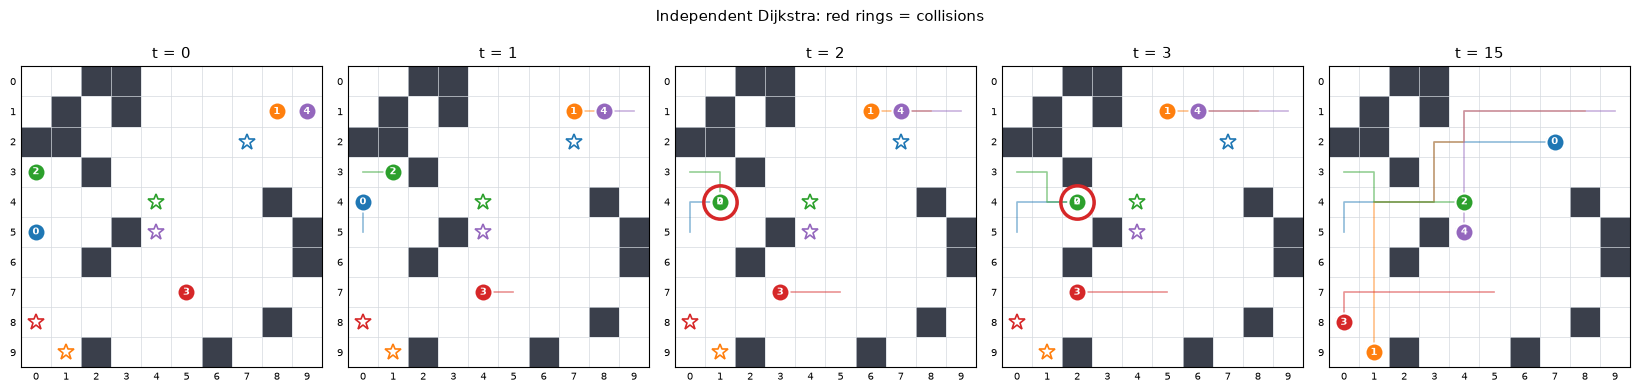

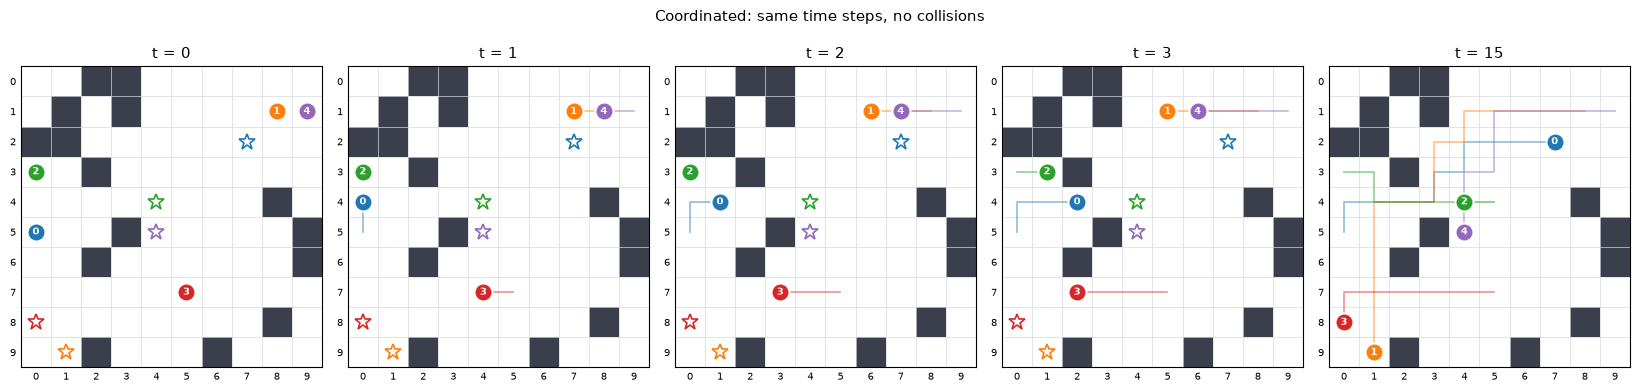

Animated GIFs saved: figures/swarm_independent.gif, figures/swarm_coordinated.gif


In [36]:
# Film strip of the 5-agent scenario. Independent plans: shown around the first collision.
label = "Scenario 2 (5 agents)"
naive_res, coord_res = plans[(label, "Independent (naive)")], plans[(label, "Coordinated")]
ev = find_conflicts(agents, naive_res.paths)
t_hit = min(e["t"] for e in ev)
times = sorted({0, max(0, t_hit - 1), t_hit, t_hit + 1, int(results[(results.scenario == label) & (results.method == "Coordinated")].completion_time.iloc[0])})
fig = plot_snapshots(env, agents, naive_res.paths, times, ev, "Independent Dijkstra: red rings = collisions")
plt.show()
fig = plot_snapshots(env, agents, coord_res.paths, times, find_conflicts(agents, coord_res.paths), "Coordinated: same time steps, no collisions")
plt.show()
try:
    os.makedirs("figures", exist_ok=True)
    save_gif(env, agents, naive_res.paths, "figures/swarm_independent.gif", ev)
    save_gif(env, agents, coord_res.paths, "figures/swarm_coordinated.gif", find_conflicts(agents, coord_res.paths))
    print("Animated GIFs saved: figures/swarm_independent.gif, figures/swarm_coordinated.gif")
except Exception as exc:
    print("GIF export skipped:", exc)

In [37]:
print("Worked example summary")
for label in scenarios:
    a = results[(results.scenario == label) & (results.method == "Independent (naive)")].iloc[0]
    b = results[(results.scenario == label) & (results.method == "Coordinated")].iloc[0]
    print(f"{label}: collisions {int(a.collisions)} -> {int(b.collisions)}; "
          f"distance {int(a.total_distance)} -> {int(b.total_distance)} (+{b.total_distance - a.total_distance:.0f}); "
          f"completion time {a.completion_time:.0f} -> {b.completion_time:.0f} steps; "
          f"reached {a.reached_pct:.0f}% -> {b.reached_pct:.0f}%")

Worked example summary
Scenario 1 (2 agents): collisions 1 -> 0; distance 25 -> 25 (+0); completion time 15 -> 15 steps; reached 100% -> 100%
Scenario 2 (5 agents): collisions 5 -> 0; distance 45 -> 47 (+2); completion time 15 -> 15 steps; reached 100% -> 100%


## 7. Test cases and validation

**7.1 Test cases with known answers.** Small hand-made worlds where the correct behaviour is clear: shortest path on an empty grid, a detour around a wall, an unreachable goal, two drones meeting head-on, a swap, a goal cell that lies on another drone's route, plus checks of the scenario generator, reproducibility and metric sanity. Any failure raises an `AssertionError`.

In [38]:
def make_env(rows):
    """Tiny hand-made worlds: '#' obstacle, '.' free."""
    return GridEnvironment([[1 if ch == "#" else 0 for ch in row] for row in rows])

def solve(env, specs):
    ag = [Agent(i, s, g) for i, (s, g) in enumerate(specs)]
    return ag, NaivePlanner(env).plan(ag), PrioritizedPlanner(env).plan(ag)

def clean(ag, res):
    ev = find_conflicts(ag, res.paths)
    return len(ev) == 0 and all(res.paths[a.id] and res.paths[a.id][-1] == a.goal for a in ag)

def test_dijkstra_empty_grid():
    env = make_env(["....."] * 5)
    path, cost = dijkstra_static(env, (0, 0), (4, 4))
    assert cost == 8 and len(path) == 9, "shortest path on an empty grid equals the Manhattan distance"

def test_dijkstra_detour_around_wall():
    env = make_env(["..#..", "..#..", "....."])
    path, cost = dijkstra_static(env, (0, 0), (0, 4))
    assert cost == 8 and valid_path(env, path, (0, 0), (0, 4)), "must go round the wall: 8 steps (Manhattan would be 4)"

def test_dijkstra_unreachable_goal():
    env = make_env([".#.", ".#.", ".#."])
    path, cost = dijkstra_static(env, (0, 0), (0, 2))
    assert path is None and cost == float("inf"), "a goal behind a full wall is unreachable"

def test_head_on_in_open_space():
    env = make_env(["...", "...", "..."])
    ag, naive, coord = solve(env, [((1, 0), (1, 2)), ((1, 2), (1, 0))])
    assert len(find_conflicts(ag, naive.paths)) > 0, "independent plans meet in the middle"
    assert clean(ag, coord), "coordinated drones pass each other without a collision"

def test_swap_conflict_detected_and_resolved():
    env = make_env(["..", ".."])
    ag, naive, coord = solve(env, [((0, 0), (0, 1)), ((0, 1), (0, 0))])
    assert any(e["type"] == "swap" for e in find_conflicts(ag, naive.paths)), "two drones exchanging cells = swap collision"
    assert clean(ag, coord), "coordinated plan avoids the swap by detouring one drone"

def test_goal_cell_of_a_parked_drone():
    env = make_env(["...", "...", "..."])     # drone 1's goal (1,1) lies on drone 0's route
    ag, naive, coord = solve(env, [((1, 0), (1, 2)), ((0, 1), (1, 1))])
    assert clean(ag, coord), "the short-trip drone must wait, then park without being run over"
    assert len(coord.paths[1]) - 1 == 2, "it waits one step and arrives at t = 2"

def test_impossible_instance_fails_gracefully():
    env = make_env(["....."])                 # one-cell-wide corridor, two drones swapping ends: impossible
    ag, naive, coord = solve(env, [((0, 0), (0, 4)), ((0, 4), (0, 0))])
    assert any(p is None for p in coord.paths.values()), "planner must report failure, not claim success"

def test_scenario_generator_invariants():
    for seed in range(100):
        e, ag = make_scenario(10, 10, 5, OBSTACLE_DENSITY, seed)
        assert len({a.start for a in ag}) == 5 and len({a.goal for a in ag}) == 5, "starts and goals are distinct"
        assert not ({a.start for a in ag} & {a.goal for a in ag}), "no start equals a goal"
        for a in ag:
            assert e.is_free(a.start) and e.is_free(a.goal), "starts/goals are on free cells"
            assert a.manhattan >= 5, "trips are not trivial"
            assert dijkstra_static(e, a.start, a.goal)[0] is not None, "every goal is reachable"

def test_reproducible_with_seed():
    e1, a1 = make_scenario(10, 10, 5, OBSTACLE_DENSITY, 7)
    e2, a2 = make_scenario(10, 10, 5, OBSTACLE_DENSITY, 7)
    e3, a3 = make_scenario(10, 10, 5, OBSTACLE_DENSITY, 8)
    assert (e1.grid == e2.grid).all() and [(a.start, a.goal) for a in a1] == [(a.start, a.goal) for a in a2]
    assert not (e1.grid == e3.grid).all() or [(a.start, a.goal) for a in a1] != [(a.start, a.goal) for a in a3]

def test_metric_sanity():
    for seed in range(40):
        e, ag = make_scenario(10, 10, 5, OBSTACLE_DENSITY, 9000 + seed)
        coord = PrioritizedPlanner(e).plan(ag)
        m = evaluate(e, ag, coord)
        longest = max(dijkstra_static(e, a.start, a.goal)[1] for a in ag)
        assert m["total_distance"] >= m["ideal_distance"], "nobody can beat the shortest path"
        assert m["completion_time"] >= longest, "mission cannot finish before the longest shortest-path trip"

def valid_path(env, path, start, goal):
    """Path starts/ends correctly, stays on free cells and moves at most one cell per step."""
    return (path[0] == start and path[-1] == goal and all(env.is_free(c) for c in path)
            and all(abs(u[0] - v[0]) + abs(u[1] - v[1]) <= 1 for u, v in zip(path, path[1:])))

tests = [v for k, v in sorted(globals().items()) if k.startswith("test_") and callable(v)]
report = []
for t in tests:
    try:
        t(); status = "PASS"
    except AssertionError as err:
        status = f"FAIL - {err}"
    report.append({"test case": t.__name__[5:].replace("_", " "), "result": status})
report = pd.DataFrame(report).set_index("test case")
assert (report.result == "PASS").all(), report
report

,result
test case,
dijkstra detour around wall,PASS
dijkstra empty grid,PASS
dijkstra unreachable goal,PASS
goal cell of a parked drone,PASS
head on in open space,PASS
impossible instance fails gracefully,PASS
metric sanity,PASS
reproducible with seed,PASS
scenario generator invariants,PASS


## 8. Quantum computing extension

**Which part of the problem could benefit?** 

Planning one drone's path is easy for a classical computer (Dijkstra is polynomial). The hard part is the **joint** decision: choosing one path per drone so that total cost is minimal *and* nobody conflicts. Optimal multi-agent path finding is NP-hard, which is why my planner fixes a priority order and plans fast, but not optimal. The part that could use a quantum or quantum-inspired optimiser is this **selection among candidate paths**: all its decisions are yes/no and its conflicts are pairwise. Paths themselves would still come from classical Dijkstra, giving a hybrid classical–quantum design.

**QUBO formulation (path selection).** Let each drone `a` have a set of candidate paths (for example from different priority orders or from k-shortest-path search). Use one binary variable `x_{a,k}`: `1` if drone `a` flies its candidate path `k`.

`H(x) = Σ c_{a,k}·x_{a,k}  +  A · Σ_a ( Σ_k x_{a,k} − 1 )²  +  B · Σ_{(a,k)~(b,l)} x_{a,k}·x_{b,l}`

* First term — **cost**: `c_{a,k}` is the path length or arrival time.
* Second term — **one path per drone**: zero only if exactly one candidate is chosen.
* Third term — **conflicts**: the sum runs over pairs of candidate paths of *different* drones that share a cell at the same time step or swap cells; each such pair is penalised (this is the *conflict graph*).

Because `x² = x` for binary variables, everything is quadratic: `H = xᵀQx` + const, with `Q_ii = c_i − A`, `Q_ij = 2A` for two candidates of the same drone, `Q_ij = B` for a conflicting pair, and 0 otherwise. This is a **QUBO** (quadratic unconstrained binary optimisation), the input form of quantum annealers and of simulated annealing; it can be rewritten as an Ising model for QAOA on gate-based machines. `A` and `B` must be large enough that breaking a rule never pays off. The number of binary variables equals the total number of candidate paths (e.g. 5 drones × 10 candidates = 50). If the conflict graph splits into connected groups of drones, each group is an independent, smaller QUBO.

**Potential advantages.** Hardware such as quantum annealers natively minimise QUBO/Ising energies and may explore many combinations in parallel; the QUBO is *only* the hard selection step, so the cheap classical parts (shortest paths) stay classical; splitting into independent components keeps problems small; quantum-inspired methods (e.g. simulated annealing) can run on ordinary computers today.

**Limitations.**
* *Size and connectivity of hardware:* qubits are scarce and only partly connected; the paper reports practical sizes of a few hundred logical qubits and that more than ~100 agents would give unreasonable results on today's annealer.
* *Penalty weights:* large `A`, `B` give coefficients with a wide range, which makes the problem harder for noisy hardware; the answer may also violate constraints (be infeasible) — the paper observed this on a real annealer in some maps.
* *Noise and no proven speed-up:* current (NISQ) devices are noisy, and there is no established quantum advantage for this problem; strong classical solvers (ILP, CBS, LaCAM\*) already exist.
* *Candidate paths are needed first:* the QUBO can only pick among paths it is given, so path generation (classical) is critical to quality.

## 9. Conclusions

* **Independent shortest paths collide, and the problem grows quickly with the number of drones.**
* **Coordination removes the collisions at a very small price.** The coordinated plans had **0 collisions in every experiment** and **100% of drones reached their goal**. The extra distance was roughly 0.5–3% with 2–5 drones, and the mission completion time was practically unchanged. Reason: the longest trips plan first and keep their shortest paths, and the shorter trips have slack in which to wait.
* **Cost:** coordinated planning is slower than independent Dijkstra because it searches in space-time and runs once per drone, but it stays well under a second in these tests.
* **Worked example (10×10, seed shown above):** Scenario 1: 1 collision → 0, no extra distance, same completion time; Scenario 2: 5 collisions → 0, +2 moves of distance (45 → 47), same completion time, all drones arrive.

**Limitations.** Prioritized planning is neither optimal nor complete; the grid is 2D and 4-connected with unit time steps; drones have no dynamics, size or safety radius; planning is centralised; "collisions" count discrete cell conflicts. The independent baseline is evaluated assuming drones fly through each other rather than crash.

**Natural extensions.** The quantum/QUBO path-selection idea of Section 8; A\* with a Manhattan heuristic for faster search; Conflict-Based Search (CBS) for optimal coordination; decentralised negotiation instead of a central table; 3D space, speed limits and safety margins; searching for a better priority order as a combinatorial optimisation problem.